# H15 Part A · Step 2b · The side-car's architecture, part by part

A companion to notebook 02 (the loss), for the questions the review raised about the model itself
([the plan](../../../docs/drivejepa-perception-sidecar-A.md), §4):

1. **`lidar2img`**: what it is, what it does to the tokens (nothing), what it does to the keys, and
   whether the side-car actually uses it;
2. **the decoder, part by part**: the N queries, their position, self-attention, cross-attention, the FFN,
   the layer-by-layer refinement: what each adds, where the design comes from, and what each does in the
   pipeline check's model;
3. **the heads**: one small network per output, and the alternatives;
4. **the readout**, and what it means for explainability;
5. **the side-car beside Drive-JEPA's two variants**.

The pictures in sections 1 and 2 use the pipeline check's checkpoint (`H15.r1`, epoch 1 of 12) on the
select logs: a model one epoch into training, so they show the mechanism, not its final form.

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2") at this site: it starts the interpreter `gallops.toml` names as
`[python] drivejepa` (Python 3.9, torch 2.1). Not `python3` ("Python 3 (ipykernel)"), which starts the system
Python without torch, and not `drive-jepa-py39`, another venv with another navsim tree first on its path.
Elsewhere, any kernel that starts `[python] drivejepa`. Headless: `scripts/run_notebooks.py`.

In [1]:
import json
import math
import os
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import evaluate, navsim_data, sidecar, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
torch.set_num_threads(16)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
NAVSIM = Path(cfg.resolve("{data.navsim}"))
RUN = RUNS / "part-a" / "r1-pipeline-v1-s0"
labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
select = np.flatnonzero(np.isin(token_logs, splits["select"]))
lidar2img = np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r"))
proj = tg.front_projection(lidar2img).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")
run = json.loads((RUN / "run.json").read_text())
model, kept = train_sidecar.load_run(RUN)
if torch.cuda.is_available():
    device = torch.device("cuda", int(np.argmax([torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())])))
else:
    device = torch.device("cpu")
model = model.to(device).eval()
print(f"checkpoint: H15.r1, epoch {kept} of 12, {sum(p.numel() for p in model.parameters()):,} parameters, on {device.type}")


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

checkpoint: H15.r1, epoch 1 of 12, 4,388,342 parameters, on cuda


## 1. `lidar2img`: what it is, and what it does

**What it is.** For each camera the vendor builds a 4 × 4 matrix, `lidar2img` (`bev_feature_build.py`): the
camera's intrinsics times its extrinsics (lidar, which in OpenScene is the ego frame, to camera), scaled by
0.4 for the padded frame the vendor's image pipeline uses. It maps a point (x, y, z, 1) in the ego frame to
(u·w, v·w, w, 1) on that frame; dividing by w gives the pixel, and w is the depth along the camera's axis.
The side-car keeps CAM_F0's (slot 1) and composes it with `TO_512`, the 28-row crop and the resize, so that
pixels are those of the 512×256 image the ViT reads (`targets.front_projection`).

**What it does to the tokens: nothing.** The ViT computes its 512 tokens from the two frames' pixels alone.
No matrix enters it, in the release or here. The release's image encoder even has the line that would add a
`lidar2img` embedding to the tokens, commented out (`image_encoder.py`, `#feat = feat +lidar2img_embed`).

**What it does in the side-car: it tells each token where it looks.** For token (r, c), the inverse of the
projection gives the camera's centre and the ray through the token's pixel centre (16c + 8, 16r + 8).
`sidecar.ray_pos` samples 16 points along that ray, 1 to 60 m, log-spaced; an MLP turns their 48 coordinates
into a 256-d vector, which is **added to the token as a key** (the "where"), while the **values** stay the
token itself (the "what"). This is PETR's idea (Liu et al., ECCV 2022): a 3D position embedding built from
camera rays, so that a query with a 3D position can find the tokens that look towards it.

**In the release**, `lidar2img` is used the other way round, BEVFormer's way (Li et al., ECCV 2022): the
refiner's spatial cross-attention projects 3D points of each proposal into the image and samples the tokens
around them (`spatial_cross_attention.py`, `reference_points_cam`). Both use geometry to decide *where to
look*; neither changes *what the tokens say*.

The rays, token by token (the select logs' first sample):

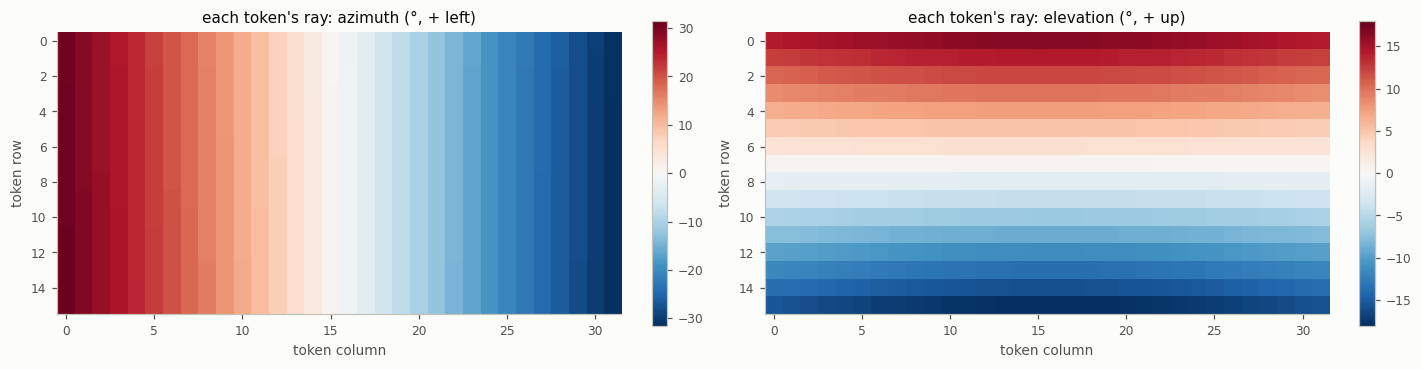

one token spans -2.00° of azimuth and 2.18° of elevation


In [2]:
def token_ray_angles(p):
    """(16, 32) azimuth and elevation (degrees) of each token's ray, ego frame (azimuth + to the left)."""
    az, el = np.zeros((16, 32)), np.zeros((16, 32))
    for r in range(16):
        for c in range(32):
            _, ray = views.camera_ray(p.astype(np.float64), 16 * c + 8, 16 * r + 8)
            az[r, c] = np.degrees(np.arctan2(ray[1], ray[0]))
            el[r, c] = np.degrees(np.arctan2(ray[2], np.hypot(ray[0], ray[1])))
    return az, el


az0, el0 = token_ray_angles(proj[select[0]])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, grid, title, cmap in ((axes[0], az0, "azimuth (°, + left)", "RdBu_r"), (axes[1], el0, "elevation (°, + up)", "RdBu_r")):
    lim = np.abs(grid).max()
    im_ = ax.imshow(grid, cmap=cmap, vmin=-lim, vmax=lim)
    ax.set_title(f"each token's ray: {title}")
    ax.set_xlabel("token column")
    ax.set_ylabel("token row")
    ax.grid(False)
    plt.colorbar(im_, ax=ax, fraction=0.025)
plt.tight_layout()
plt.show()
print(f"one token spans {np.diff(az0, axis=1).mean():.2f}° of azimuth and {-np.diff(el0, axis=0).mean():.2f}° of elevation")

**How much the geometry varies, and why that matters.** Across all 103,288 NAVSIM samples the direction of
a token's ray moves by about half a degree (standard deviation; *measured* below), a quarter of a token, and
the camera's position by 1–2 cm: every NAVSIM vehicle carries the same rig. So during training the ray
embedding is, in effect, **a fixed positional code**: it never shows the side-car a different camera, and the
side-car cannot learn from NAVSIM how to use one. nuScenes' camera differs by about a token's worth (1.4° in
azimuth, 2.1° in elevation, on average over its keyframes): a geometry input the side-car has never seen.

In [3]:
r_, c_ = np.meshgrid(np.arange(16), np.arange(32), indexing="ij")
pix = np.stack([16 * c_.ravel() + 8, 16 * r_.ravel() + 8, np.ones(512)], -1)


def ray_angles_all(P):
    Minv = np.linalg.inv(P[:, :3, :3].astype(np.float64))
    d = np.einsum("bij,pj->bpi", Minv, pix)
    return np.degrees(np.arctan2(d[..., 1], d[..., 0])), np.degrees(np.arctan2(d[..., 2], np.hypot(d[..., 0], d[..., 1])))


az_nav, el_nav = ray_angles_all(proj)
nus_l2i = np.load(RUNS / "nusc-v1" / "outputs.npz")["lidar2img"][:, tg.FRONT_SLOT].astype(np.float64)
az_nus, el_nus = ray_angles_all(tg.to_512(1600, 900) @ nus_l2i)
pd.DataFrame({
    "NAVSIM: spread over samples (std, °)": [az_nav.std(0).mean(), el_nav.std(0).mean()],
    "nuScenes: spread over keyframes (std, °)": [az_nus.std(0).mean(), el_nus.std(0).mean()],
    "nuScenes minus NAVSIM (mean over tokens, °)": [(az_nus.mean(0) - az_nav.mean(0)).mean(), (el_nus.mean(0) - el_nav.mean(0)).mean()],
}, index=["azimuth", "elevation"]).round(2)

,"NAVSIM: spread over samples (std, °)","nuScenes: spread over keyframes (std, °)","nuScenes minus NAVSIM (mean over tokens, °)"
azimuth,0.51,0.32,1.39
elevation,0.48,0.11,2.05


**Why two degrees of elevation is a lot.** Beyond 20 m an agent sits within one or two token rows of the
horizon (notebook 01 §4), so its distance rests on how far below the horizon its base appears. For a camera
1.52 m up, an error of ε in that angle moves the ground point as follows:

In [4]:
h = 1.52
rows_ = []
for D in (10, 20, 30, 50):
    theta = math.degrees(math.atan(h / D))
    row = {"true distance (m)": D, "angle below the horizon (°)": round(theta, 2)}
    for eps in (-2, -1, 1, 2):
        row[f"{eps:+d}°"] = round(h / math.tan(math.radians(theta + eps)), 1) if theta + eps > 0 else math.inf
    rows_.append(row)
pd.DataFrame(rows_).set_index("true distance (m)")

,angle below the horizon (°),-2°,-1°,+1°,+2°
true distance (m),,,,,
10,8.64,13.1,11.3,8.9,8.1
20,4.35,37.1,26.0,16.2,13.7
30,2.90,96.7,45.8,22.3,17.7
50,1.74,inf,117.5,31.7,23.2


At 20 m, an error of one degree puts the agent at 16 or 26 m, and two degrees at 14 or 37 m. A side-car that has only ever seen one camera
can either have learnt "this token row is 20 m away" (memorised, wrong for another camera) or "this ray meets
the road 20 m away" (geometric, right for any camera). The next cell asks the checkpoint which.

**Does the side-car use the rays?** Three changes to the geometry input only, the tokens untouched, read on
the select logs:
- **yaw ±2°**: the projection turned about the ego's vertical axis. A side-car that places agents by their
  rays turns its detections by the same 2° (and loses recall, since the labels did not turn); one that has
  memorised each token's place ignores it;
- **pitch +2°**: the projection tilted; a geometric side-car moves distant agents a long way (the table above);
- **no rays**: the ray embedding removed from the keys (keys = token content only).

In [5]:
def run_select(model, rows, projections, ray_scale=1.0, batch=128):
    """The last layer's raw outputs on `rows`, with the given projections (and the ray embedding scaled)."""
    out = {k: [] for k in ("logits", "box", "vel", "path")}
    if ray_scale != 1.0:
        original = model.ray_pos  # the bound method; an instance attribute shadows it until deleted
        model.ray_pos = lambda p: original(p) * ray_scale
    try:
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            for i in range(0, len(rows), batch):
                chunk = rows[i : i + batch]
                tok = torch.from_numpy(np.stack([np.asarray(vit[r], dtype=np.float16) for r in chunk])).to(device)
                if device.type == "cpu":
                    tok = tok.float()
                o = model(tok, torch.from_numpy(projections[i : i + batch]).to(device))[-1]
                for k in out:
                    out[k].append(o[k].float().cpu().numpy())
    finally:
        if ray_scale != 1.0:
            del model.ray_pos  # back to SideCar.ray_pos
    return {k: np.concatenate(v) for k, v in out.items()}


def rotate(P, yaw_deg=0.0, pitch_deg=0.0):
    """Projections composed with a rotation of the ego frame: what the camera would be if turned."""
    a, b = math.radians(yaw_deg), math.radians(pitch_deg)
    rz = np.array([[math.cos(a), -math.sin(a), 0, 0], [math.sin(a), math.cos(a), 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
    ry = np.array([[math.cos(b), 0, math.sin(b), 0], [0, 1, 0, 0], [-math.sin(b), 0, math.cos(b), 0], [0, 0, 0, 1]])
    return (P.astype(np.float64) @ (rz @ ry)).astype(np.float32)


gts = [targets_of(r) for r in select]
P_sel = proj[select]
cases = {
    "as recorded": (P_sel, 1.0),
    "yaw +2°": (rotate(P_sel, yaw_deg=2.0), 1.0),
    "yaw −2°": (rotate(P_sel, yaw_deg=-2.0), 1.0),
    "pitch +2°": (rotate(P_sel, pitch_deg=2.0), 1.0),
    "no rays in the keys": (P_sel, 0.0),
}
raw_by_case, read_by_case = {}, {}
for name, (P, scale) in cases.items():
    raw = run_select(model, select, P, ray_scale=scale)
    preds = [evaluate.decode({k: v[i] for k, v in raw.items()}) for i in range(len(select))]
    raw_by_case[name] = raw
    read_by_case[name] = evaluate.readout(preds, gts, run["prior_gap_m"])


def turn(name):
    """Mean change of detection azimuth against the recorded case, per slot detected in both (°)."""
    base, other = raw_by_case["as recorded"], raw_by_case[name]
    cb = 1 - torch.softmax(torch.from_numpy(base["logits"]), -1)[..., tg.NONE].numpy()
    co = 1 - torch.softmax(torch.from_numpy(other["logits"]), -1)[..., tg.NONE].numpy()
    both = (cb >= 0.5) & (co >= 0.5)
    a_b = np.degrees(np.arctan2(base["box"][..., 1], base["box"][..., 0]))[both]
    a_o = np.degrees(np.arctan2(other["box"][..., 1], other["box"][..., 0]))[both]
    r_b = np.hypot(base["box"][..., 0], base["box"][..., 1])[both]
    r_o = np.hypot(other["box"][..., 0], other["box"][..., 1])[both]
    return float(np.mean(a_o - a_b)), float(np.median(r_o / np.maximum(r_b, 1e-3)))


table = {}
for name, r in read_by_case.items():
    shift, ratio = turn(name) if name != "as recorded" else (0.0, 1.0)
    table[name] = {"recall within 30 m": r["recall_2m_within_30m"], "precision within 30 m": r["precision_2m_within_30m"],
                   "centre error of hits (m)": r["centre_error_m"], "detections turn by (°, mean)": shift,
                   "detections' range ×(median)": ratio}
pd.DataFrame(table).T

,recall within 30 m,precision within 30 m,centre error of hits (m),"detections turn by (°, mean)",detections' range ×(median)
as recorded,0.405,0.578,1.029,0.000,1.000
yaw +2°,0.405,0.580,1.028,0.009,1.000
yaw −2°,0.405,0.578,1.029,-0.011,1.000
pitch +2°,0.396,0.587,1.019,-0.131,1.003
no rays in the keys,0.358,0.593,1.035,-0.113,1.005


**Reading it** (one epoch into training: a first answer, to be read again on step 5's trained models):
- **Turning the camera by 2° turns the detections by about 0.01°, and tilting it barely changes their
  range.** The side-car does not place agents by their rays. It places them by what the tokens say, and
  the tokens carry their own position already, through the ViT's positional encoding.
- **Yet the rays are not idle: removing them costs 0.047 recall.** They act as a fixed positional code,
  which is all NAVSIM's single camera (0.5° of spread) can teach.
- **What follows for nuScenes:** its camera differs by about a token (1.4° in azimuth, 2.1° in
  elevation). A side-car that ignores geometry will place nuScenes' agents as if the camera were NAVSIM's,
  and at 20 m two degrees of elevation is the difference between 14 and 37 m (the table above).
- **The remedy to test at step 7 (plan §4.1):** the cameras differ by a rotation, the intrinsics and a few
  centimetres. A rotation and a change of intrinsics are undone exactly by warping the image (a
  homography) to NAVSIM's camera before the ViT. The side-car then sees the geometry it was trained on.

## 2. The decoder, part by part

![The side-car](../figures/part-a-sidecar.png)

| Part | What it adds | Where it comes from |
|---|---|---|
| **N queries** (64 in v1): learned vectors, one per *slot* | A fixed set of "agent slots" the decoder fills; each slot outputs one agent or "none". The output is a **set**: no anchors, no non-maximum suppression | DETR's object queries (Carion et al., ECCV 2020) |
| **reference points** (one 3D point per slot) and the **query position** MLP | Gives each slot a place: a 3D point, embedded and added to the slot's query, so attention can be *spatial* ("look near here"), not content alone | Deformable DETR's reference points (Zhu et al., ICLR 2021); 3D reference points in DETR3D (Wang et al., CoRL 2021); conditional / anchor queries (Meng et al., ICCV 2021; Liu et al., ICLR 2022) |
| **self-attention** among the slots | Slots see each other: two slots on one agent can split the work, so the set has no duplicates. This is what lets DETR drop NMS | DETR (its decoder ablation: removing self-attention leaves duplicates) |
| **cross-attention** to the 512 tokens | Each slot gathers evidence from the image. Keys are token content **plus its ray** (§1), values are content: the slot's position chooses where to look, the tokens say what is there | DETR's cross-attention; keys with 3D ray embeddings from PETR (Liu et al., ECCV 2022) |
| **FFN** per slot | Per-slot computation between attention steps | the Transformer (Vaswani et al., NeurIPS 2017) |
| **iterative refinement**: each layer's centre is the next layer's reference, detached | Each layer moves its slot's 3D point closer to the agent, and the next layer looks again from there. Detaching stops the next layer's loss from pushing the previous layer's box, which Deformable DETR found steadier | Deformable DETR's box refinement; DETR3D's iterative refinement |
| **heads on every layer**, each layer supervised | The loss reaches every layer directly (deep supervision): faster, steadier training | DETR's auxiliary decoding losses |

The side-car is H04's `AgentDecoder` (Navvrat, branch `drivejepa-wajepa/run3a`), written in this lineage
for WA-JEPA's four cameras, reduced to one camera here. Its arrangement (PETR-style keys, DETR3D-style 3D
reference points, DETR's set loss) is the standard camera-only 3D detector of 2021–2023 (DETR3D, PETR,
StreamPETR: Wang et al., ICCV 2023), small enough to sit beside a frozen encoder.

**What each part does in the checkpoint.** Re-running the forward pass by hand, so the attention weights
can be read, and holding it to the model's own output first:

In [6]:
def attention(mha, q_in, k_in):
    """(B, heads, Nq, Nk) attention weights of `mha` (sidecar.MHA) for these inputs."""
    b, nq, d = q_in.shape
    dh = d // mha.h
    q = mha.q(q_in).view(b, nq, mha.h, dh).transpose(1, 2)
    k = mha.k(k_in).view(b, -1, mha.h, dh).transpose(1, 2)
    return torch.softmax(q @ k.transpose(-1, -2) / math.sqrt(dh), dim=-1)


@torch.no_grad()
def trace(model, tokens, projection):
    """sidecar.SideCar.forward, written out layer by layer, keeping what each part produced (eval mode)."""
    mem = model.ln_tok(model.proj(tokens))
    keys = mem + model.ray_pos(projection)
    a = model.query[None].expand(len(tokens), -1, -1)
    ref = model.ref[None].expand(len(tokens), -1, -1)
    steps = []
    for layer in model.layers:
        pos = model.pos_mlp(ref * model.scale)
        h = layer.ln_sa(a)
        sa = attention(layer.sa, h + pos, h + pos)
        a = a + layer.sa(h + pos, h + pos, h)
        q_in = layer.ln_ca(a) + pos
        ca = attention(layer.ca, q_in, keys)
        a = a + layer.ca(q_in, keys, mem)
        a = a + layer.ffn(layer.ln_ff(a))
        centre = ref + layer.ref_mlp(a)
        kept = {"reference": ref, "centre": centre, "self": sa, "cross": ca, "logits": layer.cls_head(a)}
        steps.append({key: value.detach() for key, value in kept.items()})
        ref = centre
    return steps


picked = [int(r) for r in np.random.default_rng(6).permutation(select) if 5 <= targets_of(r)["mask"].sum() <= 15][:2]
tok = torch.from_numpy(np.stack([np.asarray(vit[r], dtype=np.float32) for r in picked])).to(device)
P = torch.from_numpy(proj[picked]).to(device)
steps = trace(model, tok, P)
with torch.no_grad():
    ref_out = model(tok, P)[-1]
assert torch.allclose(steps[-1]["centre"], ref_out["box"][..., :3], atol=1e-4)
assert torch.allclose(steps[-1]["logits"], ref_out["logits"], atol=1e-4)
print("the hand-written forward equals the model's (centres and logits, to 1e-4)")

the hand-written forward equals the model's (centres and logits, to 1e-4)


**Cross-attention: where each detected slot looked.** For the first sample: each detection's last-layer
attention over the 512 tokens (averaged over the 8 heads), drawn on the image the ViT read, beside the
detection's box. The rays put a slot's attention near its 3D point; the content decides where exactly.

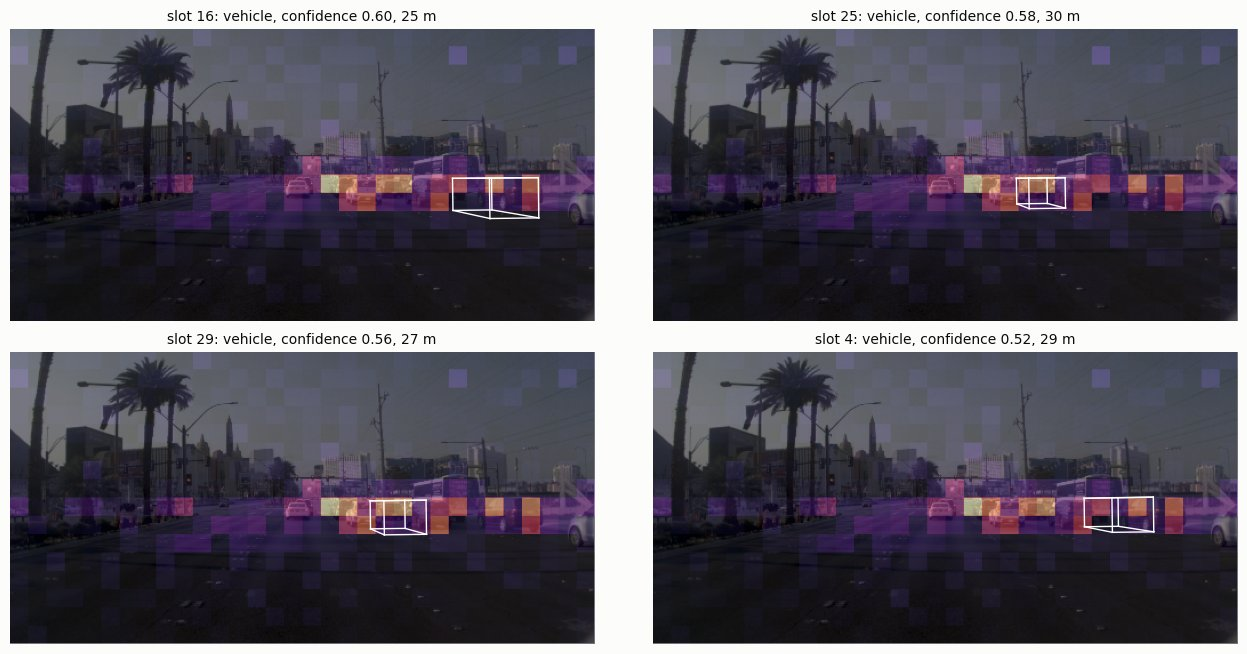

In [7]:
row = picked[0]
frame = views.window_frames(NAVSIM, str(token_logs[row]), str(labels["token"][row]))[navsim_data.CURRENT]
image = views.model_view(views.read_image(views.camera_path(NAVSIM, frame)))
logits = steps[-1]["logits"][0].float().cpu()
conf = 1 - torch.softmax(logits, -1)[:, tg.NONE].numpy()
shown = np.argsort(-conf)[:4]
cross = steps[-1]["cross"][0].mean(0).float().cpu().numpy()  # slots x 512
centres = steps[-1]["centre"][0].float().cpu().numpy()
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6))
for ax, q in zip(axes.ravel(), shown):
    ax.imshow(image)
    heat = cross[q].reshape(16, 32)
    ax.imshow(np.kron(heat / heat.max(), np.ones((16, 16))), cmap="magma", alpha=0.55, extent=(0, 512, 256, 0))
    box = np.r_[centres[q], np.exp(ref_out["box"][0, q, 3:6].float().cpu().numpy()),
                math.atan2(float(ref_out["box"][0, q, 6]), float(ref_out["box"][0, q, 7]))]
    for (u0, v0), (u1, v1) in views.box_edges_2d(proj[row], box[None])[0]:
        ax.plot([u0, u1], [v0, v1], color="white", lw=1.0)
    cls = int(np.argmax(torch.softmax(logits[q], -1)[: tg.NONE].numpy()))
    ax.set_title(f"slot {q}: {views.CLASS_NAMES[cls]}, confidence {conf[q]:.2f}, {np.hypot(*centres[q, :2]):.0f} m")
    ax.set_xlim(0, 512)
    ax.set_ylim(256, 0)
    ax.axis("off")
plt.tight_layout()
views.show_jpeg(fig)

**What it shows, one epoch in:** the four detected slots attend to the same band of tokens along the
horizon, where the vehicles are, rather than each to its own vehicle. The attention is not yet specific to
a slot; their boxes differ mainly because each slot starts from its own reference point. Whether attention
becomes specific is read on step 5's models with this same cell.

**Self-attention: which slots listen to which.** The first sample's last-layer self-attention (mean over
heads), slots sorted by confidence. Most slots attend to the detected ones (the dark columns on the left):
every slot looks at the slots that hold agents, which is where it can learn that its agent is taken.

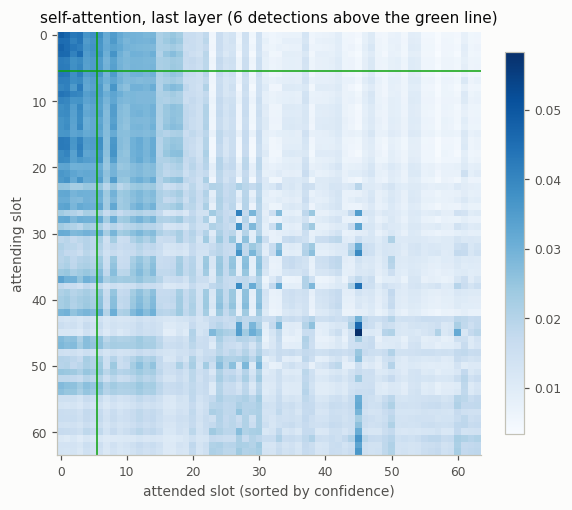

In [8]:
order = np.argsort(-conf)
sa = steps[-1]["self"][0].mean(0).float().cpu().numpy()[np.ix_(order, order)]
n_det = int((conf >= 0.5).sum())
fig, ax = plt.subplots(figsize=(5.6, 5.0))
im_ = ax.imshow(sa, cmap="Blues")
ax.axhline(n_det - 0.5, color=views.HIT, lw=1.0)
ax.axvline(n_det - 0.5, color=views.HIT, lw=1.0)
ax.set_xlabel("attended slot (sorted by confidence)")
ax.set_ylabel("attending slot")
ax.set_title(f"self-attention, last layer ({n_det} detections above the green line)")
ax.grid(False)
plt.colorbar(im_, ax=ax, fraction=0.04)
plt.show()

**Refinement: how each layer moves a slot.** For the same sample, from above: each detected slot's
reference point (where it starts, ○), its centre after each layer (·), and the target it ended nearest to (□).

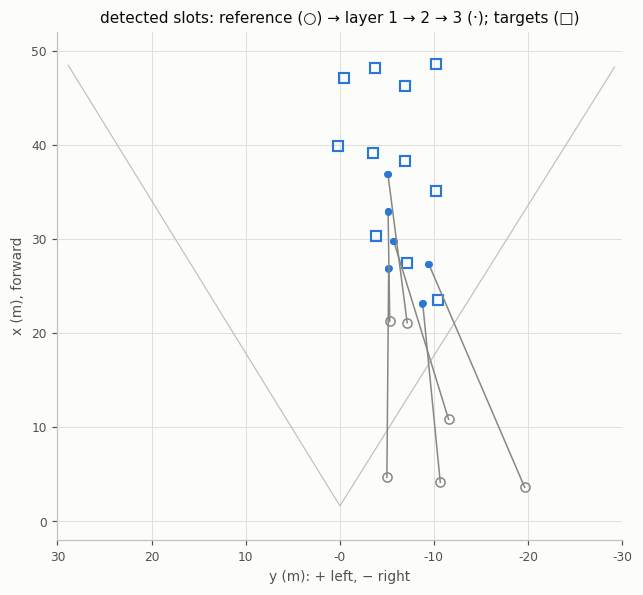

mean move of detected slots per layer (m): [19.14, 0.03, 0.07]


In [9]:
t = targets_of(row)
m = t["mask"]
fig, ax = plt.subplots(figsize=(7.0, 6.0))
edges = views.view_edges(proj[row], reach=55)
ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.AXIS, lw=0.8)
for k in np.flatnonzero(m):
    ax.plot(-t["box"][k, 1], t["box"][k, 0], "s", ms=6, mfc="none", mec=views.CLASS_COLOURS[t["cls"][k]], mew=1.4)
for q in np.flatnonzero(conf >= 0.5):
    path = [steps[0]["reference"][0, q].float().cpu().numpy()] + [s["centre"][0, q].float().cpu().numpy() for s in steps]
    path = np.array(path)
    ax.plot(-path[:, 1], path[:, 0], "-", color=views.GREY, lw=1.0)
    ax.plot(-path[0, 1], path[0, 0], "o", ms=6, mfc="none", mec=views.GREY)
    ax.plot(-path[1:, 1], path[1:, 0], ".", ms=7, color=views.CLASS_COLOURS[0])
ax.set_xlim(-30, 30)
ax.set_ylim(-2, 52)
ax.set_aspect("equal")
y_axis_left(ax)
ax.set_title("detected slots: reference (○) → layer 1 → 2 → 3 (·); targets (□)")
plt.show()
moves = [np.linalg.norm((s["centre"] - s["reference"])[0, conf >= 0.5].float().cpu().numpy(), axis=-1).mean() for s in steps]
print("mean move of detected slots per layer (m):", [round(float(v), 2) for v in moves])

**The first layer makes the jump**, 19 m on average, from each slot's fixed reference to the region of the
agents. **One epoch in, the second and third layers move the slots by only 3 and 7 cm.** Iterative
refinement is meant to let the later layers correct the first, and so far they barely do. Step 5's models
answer whether they learn to: their per-layer loss curves (notebook 03) and this picture, run again.

## 3. The heads: one small network per output

**What the side-car does now.** Every slot's 256-d vector, after each layer, goes to five separate heads:
a linear layer for the class (4 logits), and two-layer MLPs (256 → 256 → n) for the centre's change (3), the
box (log l, log w, log h, sin yaw, cos yaw), the velocity (2) and the path (2 steps × 2). So it is **not** "one
long vector of logits, decoded": each output has its own small network on a shared representation, as in
DETR (a linear class head and a 3-layer box MLP).

**The options**, from least to most specialised (none is in v1, which stays the first pass's design):

| Option | What changes | Why it might help | Cost and risk |
|---|---|---|---|
| one linear layer for everything, then decode | all outputs from one matrix | fewest parameters | outputs compete for one linear map; nothing gained here |
| deeper or wider per-task MLPs | each head 3 layers, or wider | more capacity where a task needs it (paths) | small; overfits if data-limited (A2 said it is) |
| **path as a correction to constant velocity** | path = velocity × t + learnt offset | the first pass's paths barely beat constant velocity; this makes constant velocity the default and the head learns only the deviation | none: same outputs, one line in the decode |
| **yaw relative to the ray** (allocentric) | predict the angle between heading and the token ray; add the ray's azimuth | appearance shows the allocentric angle: a car seen side-on looks the same anywhere in the image (Mousavian et al., CVPR 2017) | needs the ray in the head |
| **size from a class prior** | predict log(size / class mean) | the first layer starts near the right size | a constant per class |
| **depth along the ray** (distance, or bins) | place the centre by depth on its token's ray, not x, y freely | depth is the hard part (§1); bins + residual handle the ambiguity | changes the refinement |
| **uncertainty** per output (Laplace scale) | each regression also outputs a spread b; loss L1/b + log b | calibrated "how sure" per box and path; down-weights hopeless (hidden, far) targets automatically (Kendall & Gal, NeurIPS 2017) | a new output to read |
| **several paths per agent** (K modes) | K path heads + a mode score; winner-takes-all loss | an agent at a junction may turn or go on; one L1 path averages them | mode collapse risk (notebook 02 §8) |

The plan (§4.3) proposes testing the two that change no interface first: path as a correction to constant
velocity, and uncertainty outputs.

## 4. The readout, and explainability

**The readout** is the step after the network: it turns the last layer's raw outputs into the list a person
or a planner reads (`evaluate.decode`): confidence = 1 − p(none), class = the most likely of the three,
centre, size and yaw from the box, velocity, and the path as centre + offsets; a slot is a **detection** when
its confidence is at least 0.5.

**What it changes**: nothing in training. The loss reads every layer's raw outputs; the readout reads only
the last layer. It decides what the side-car *says*: the threshold, the last layer only, one class per slot.

**Why it matters for explainability.** A planner that reads this list can be asked *which* agent it reacted to,
and the list can be checked against the image. Each detection also carries its cross-attention (section 2):
the tokens it was built from. So every agent the side-car reports comes with "where it looked", which is
what makes the list checkable rather than a black box. What the readout cannot show is what the slot did *not*
report: a missed agent leaves no trace, which is why the plan measures recall by range, class and importance.

**Options** (plan §8.1, proposed): a confidence that means a probability (calibration, notebook 04 §4c),
per-class thresholds, and uncertainty per box (section 3).

## 5. The side-car beside Drive-JEPA's two variants

Drive-JEPA comes in two settings (its README): **perception-free**, the V-JEPA ViT with "a simple
transformer-based decoder", and **perception-based**, the full planner the release is (H15's base). Read in
the code (`navsim_v1/.../drive_jepa_perception_free/`, `navsim_v2/.../drive_jepa_perception_based/`):

| | Perception-free | Perception-based (the release) | The side-car |
|---|---|---|---|
| Image encoder | V-JEPA ViT-L, frozen | V-JEPA ViT-L + FPN neck to 256 (the "projector") | the release's ViT output, frozen |
| Image tokens | 16 × 32, average-pooled 2 × 2, + a linear map | 16 × 32, 256-d after the neck | 16 × 32, 1024 → 256 |
| Camera geometry | none: a learnt embedding per token position | `lidar2img` projects 3D proposal points into the image to sample it (BEVFormer's spatial cross-attention) | `lidar2img` → each token's ray → added to the keys (PETR's position embedding) |
| Ego status | one extra token | added to every proposal query | not an input |
| Queries | 8, one per future pose | 32 proposals × 8 poses, refined 4 times | 64 (or 128) agent slots with 3D reference points |
| Attention | `nn.Transformer`: encoder over tokens, decoder over queries | deformable self-attention among proposals, deformable image cross-attention | standard self-attention among slots, full cross-attention to all 512 tokens |
| Outputs at inference | one trajectory | 32 proposals, 6 scores, the pick | a list of agents: class, 3D box, velocity, 1 s path |
| Perception | none | **training-only** auxiliaries (`if self.training`): collision agents per proposal, drivable area (config `agent_pred`, `area_pred`); BEV map and BEV agents are off in v2 | perception is its whole output, at inference |
| Loss | trajectory L1, normalised by length (`l1_length_normalized_loss`) | winner-takes-all over proposals + distilled anchors, PDM-score BCE, auxiliaries | Hungarian set loss: focal + L1 terms |

**Where the side-car is the same**: it reads the same frozen ViT, the same two frames, the same camera
geometry, and uses the same building blocks (learnt queries, attention to image tokens, MLP heads).

**Where it differs**: it predicts the agents themselves, at inference, as a list a person can read; the
release's perception exists only as training signals for its planner and is discarded at inference, and the
perception-free variant has none. And it is separate from the planner: nothing it does changes the plan,
which is what lets Part A be measured on its own.